# Baseline system inputs: fuel and CO$_2$ prices, installed capacities

Publication figures for the six Ariadne pathways (2030, 2035, 2040, 2045). Both figures describe the **baseline**
(Ariadne / PyPSA-DE) system that ASSUME simulates *before* the sector demands are added:

1. **Figure 1**: fuel and CO$_2$ prices of each pathway.
2. **Figure 2**: installed generation capacity, storage power and storage energy by technology.

All numbers are read from the ASSUME input folders `examples/inputs/steel_base/<pathway>_<year>/`
(`fuel_prices_df.csv`, `powerplant_units.csv`, `storage_units.csv`), which were extracted from the solved PyPSA-DE networks.
Figures are written to `figures/` as vector PDF (for the manuscript) and 300 dpi PNG, together with the plotted data as CSV.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

INPUTS = Path("..") / "inputs" / "steel_base"
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)

import actor_impact_utils as aiu   # single source of the paper naming convention

PATHWAYS = {fam: aiu.pathway_label(fam) for fam in aiu.FAMILIES}   # folder name -> figure label (e.g. fokusH2 -> H₂)
YEARS = [2030, 2035, 2040, 2045]

from matplotlib import font_manager as fm
for f in Path("/usr/share/fonts/truetype/liberation").glob("LiberationSans-*.ttf"):
    fm.fontManager.addfont(str(f))

# Journal style: sans-serif (Arial metric), 7-8 pt text, embedded TrueType fonts in PDF, thin axes.
mpl.rcParams.update({
    "font.family": ["Liberation Sans", "Arial", "DejaVu Sans"],
    "mathtext.default": "regular",
    "font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#DDDDDD", "grid.linewidth": 0.5,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300,
})
print("matplotlib", mpl.__version__)

matplotlib 3.11.1


## 1. Fuel and CO$_2$ prices

In [2]:
PRICE_COLS = ["co2", "natural gas", "hard coal", "lignite", "oil", "biomass", "hydrogen"]
rows = []
for fam in PATHWAYS:
    for y in YEARS:
        f = pd.read_csv(INPUTS / f"{fam}_{y}" / "fuel_prices_df.csv", index_col=0, parse_dates=True)
        f = f[f.index.year == y]                       # drop the one-day warm-up padding of the previous year
        for c in PRICE_COLS:
            if c in f.columns and f[c].notna().any():
                rows.append(dict(pathway=fam, year=y, carrier=c, mean=f[c].mean(),
                                 p05=f[c].quantile(0.05), p95=f[c].quantile(0.95),
                                 min=f[c].min(), max=f[c].max(), hours=len(f)))
prices = pd.DataFrame(rows)
shown = prices.assign(pathway_folder=prices.pathway, pathway=prices.pathway.map(aiu.pathway_label))   # paper label + original folder name
shown.round(2).to_csv(FIGDIR / "fig1_fuel_co2_prices_data.csv", index=False)
shown.pivot_table(index=["carrier", "pathway"], columns="year", values="mean").round(1)

year                  2030   2035   2040   2045
carrier     pathway                            
biomass     Elec      76.7  104.5  105.1   85.9
            ExPol     71.0   76.4   53.4   42.0
            HighDem   78.1  105.8  114.6   91.6
            H₂        76.6  104.3  107.6   82.3
            LowDem    73.6  102.3  102.4   74.3
            Mix       76.7  104.5  108.6   85.7
co2         Elec     165.5  493.3  530.7  386.4
            ExPol     -0.0   -0.0   -0.0   -0.0
            HighDem  177.6  508.1  562.8  414.2
            H₂       169.6  454.6  441.9  366.2
            LowDem   142.7  466.9  517.4  340.5
            Mix      167.8  497.5  543.5  397.7
hard coal   Elec       6.2    6.3    6.3    6.4
            ExPol      6.2    6.3    6.3    6.4
            HighDem    6.2    6.3    6.3    6.4
            H₂         6.2    6.3    6.3    6.4
            LowDem     6.2    6.3    6.3    6.4
            Mix        6.2    6.3    6.3    6.4
hydrogen    Elec      85.4  113.6  110.0   95.6
            ExPol     57.9   41.8   41.7   42.0
            HighDem   88.7  115.5  111.9   98.5
            H₂        86.6  115.5  112.2   91.6
            LowDem    79.2  113.3  108.3   91.4
            Mix       86.1  114.7  110.6   96.8
lignite     Elec       3.3    3.3    3.3    NaN
            ExPol      3.3    3.3    3.3    NaN
            HighDem    3.3    3.3    3.3    NaN
            H₂         3.3    3.3    3.2    NaN
            LowDem     3.3    3.3    3.3    NaN
            Mix        3.3    3.3    3.3    NaN
natural gas Elec      24.6   27.4   27.9   27.0
            ExPol     24.0   23.8   23.7   23.9
            HighDem   24.7   27.5   28.2   27.2
            H₂        24.6   27.5   28.1   26.8
            LowDem    24.4   27.2   27.8   26.6
            Mix       24.6   27.5   28.0   27.1
oil         Elec      85.7  174.2  184.1  146.6
            ExPol     65.7   56.9   44.0   44.6
            HighDem   89.0  178.2  192.8  152.3
            H₂        86.9  176.2  188.1  139.3
            LowDem    79.6  167.1  180.5  132.4
            Mix       86.4  175.4  187.6  147.9

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (5,616 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


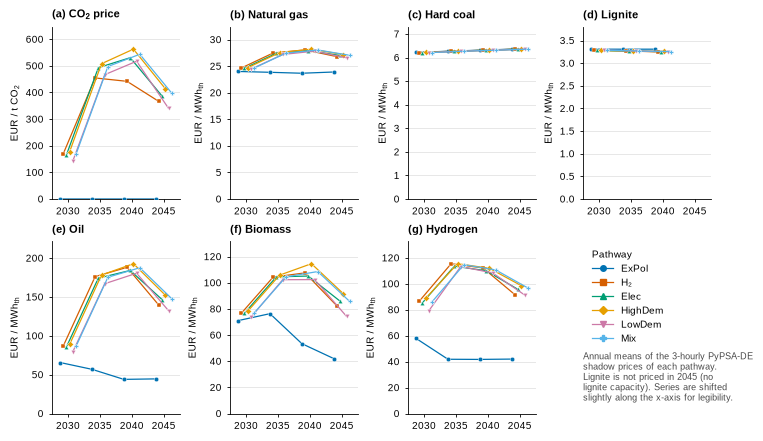

In [3]:
COLORS = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]   # Okabe-Ito, colour-blind safe
MARKERS = ["o", "s", "^", "D", "v", "P"]
PANELS = [
    ("co2",         "(a) CO$_2$ price",      "EUR / t CO$_2$"),
    ("natural gas", "(b) Natural gas",       "EUR / MWh$_{th}$"),
    ("hard coal",   "(c) Hard coal",         "EUR / MWh$_{th}$"),
    ("lignite",     "(d) Lignite",           "EUR / MWh$_{th}$"),
    ("oil",         "(e) Oil",               "EUR / MWh$_{th}$"),
    ("biomass",     "(f) Biomass",           "EUR / MWh$_{th}$"),
    ("hydrogen",    "(g) Hydrogen",          "EUR / MWh$_{th}$"),
]
offsets = np.linspace(-1.25, 1.25, len(PATHWAYS))     # small horizontal dodge so overlapping series stay visible

fig, axes = plt.subplots(2, 4, figsize=(7.5, 4.3), constrained_layout=True)
for ax, (carrier, title, unit) in zip(axes.flat, PANELS):
    for i, fam in enumerate(PATHWAYS):
        d = prices[(prices.pathway == fam) & (prices.carrier == carrier)].set_index("year")["mean"].reindex(YEARS)
        ax.plot(np.array(YEARS) + offsets[i], d.values, color=COLORS[i], marker=MARKERS[i],
                ms=3.2, lw=0.9, mfc=COLORS[i], mec="white", mew=0.3, zorder=3)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel(unit)
    ax.set_xticks(YEARS); ax.set_xlim(2027.5, 2047.5)
    ymax = prices[prices.carrier == carrier]["mean"].max()
    ax.set_ylim(0, ymax * 1.15)
    ax.grid(axis="x", visible=False)
ax_leg = axes.flat[7]; ax_leg.axis("off")
handles = [Line2D([], [], color=COLORS[i], marker=MARKERS[i], ms=4, lw=0.9, label=lab) for i, lab in enumerate(PATHWAYS.values())]
ax_leg.legend(handles=handles, loc="upper left", frameon=False, title="Pathway", alignment="left", handlelength=2.2)
ax_leg.text(0.0, 0.06,
    "Annual means of the 3-hourly PyPSA-DE\nshadow prices of each pathway.\n"
    "Lignite is not priced in 2045 (no\nlignite capacity). Series are shifted\nslightly along the x-axis for legibility.",
    transform=ax_leg.transAxes, fontsize=6.3, va="bottom", color="#444444")
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig1_fuel_co2_prices.{ext}", bbox_inches="tight")
plt.show()

**Caption (suggested).** Fuel and CO$_2$ prices in the six Ariadne pathways. Values are annual means of the PyPSA-DE shadow prices
(three-hourly resolution) used as fuel and emission costs in the ASSUME baseline. Hard coal and lignite are nearly identical across pathways;
the CO$_2$ price is close to zero in the Existing Policies pathway (ExPol) in all years (the CO$_2$ constraint is not binding in the PyPSA-DE solution).

## 2. Installed generation and storage capacity

In [4]:
GEN_GROUP = {
    "hard coal": "Hard coal", "lignite": "Lignite", "oil": "Oil",
    "gas power plant": "Gas (CCGT, OCGT, other)", "combined cycle gas turbine": "Gas (CCGT, OCGT, other)",
    "open cycle gas turbine": "Gas (CCGT, OCGT, other)",
    "urban central H2 CHP": "Hydrogen CHP", "urban central H2 retrofit CHP": "Hydrogen CHP",
    "biomass": "Biomass and waste", "waste": "Biomass and waste",
    "run-of-river hydro": "Run-of-river hydro",
    "onshore wind": "Onshore wind", "offshore wind AC": "Offshore wind", "offshore wind DC": "Offshore wind",
    "solar": "Solar PV",
}
GEN_ORDER = ["Hard coal", "Lignite", "Oil", "Gas (CCGT, OCGT, other)", "Hydrogen CHP", "Biomass and waste",
             "Run-of-river hydro", "Onshore wind", "Offshore wind", "Solar PV"]          # bottom -> top
GEN_COLOR = {"Hard coal": "#3B3B3B", "Lignite": "#8C6D31", "Oil": "#9A9A9A", "Gas (CCGT, OCGT, other)": "#D55E00",
             "Hydrogen CHP": "#CC79A7", "Biomass and waste": "#8FB339", "Run-of-river hydro": "#009E73",
             "Onshore wind": "#0072B2", "Offshore wind": "#56B4E9", "Solar PV": "#E69F00"}
STO_GROUP = {"battery": "Battery", "PSPP": "Pumped hydro", "hydro storage": "Hydro reservoir"}
STO_ORDER = ["Battery", "Pumped hydro", "Hydro reservoir"]
STO_COLOR = {"Battery": "#882255", "Pumped hydro": "#44AA99", "Hydro reservoir": "#DDCC77"}

rows = []
for fam in PATHWAYS:
    for y in YEARS:
        base = INPUTS / f"{fam}_{y}"
        p = pd.read_csv(base / "powerplant_units.csv")
        unmapped = set(p.technology) - set(GEN_GROUP)
        assert not unmapped, f"unmapped generation technologies: {unmapped}"
        for g, v in p.assign(g=p.technology.map(GEN_GROUP)).groupby("g").max_power.sum().items():
            rows.append(dict(pathway=fam, year=y, kind="generation_GW", group=g, value=v / 1e3))
        s = pd.read_csv(base / "storage_units.csv")
        unmapped = set(s.technology) - set(STO_GROUP)
        assert not unmapped, f"unmapped storage technologies: {unmapped}"
        s["g"] = s.technology.map(STO_GROUP)
        for g, v in s.groupby("g").max_power_discharge.sum().items():
            rows.append(dict(pathway=fam, year=y, kind="storage_power_GW", group=g, value=v / 1e3))
        for g, v in s.groupby("g").capacity.sum().items():
            rows.append(dict(pathway=fam, year=y, kind="storage_energy_GWh", group=g, value=v / 1e3))
cap = pd.DataFrame(rows)
cap_shown = cap.assign(pathway_folder=cap.pathway, pathway=cap.pathway.map(aiu.pathway_label))   # paper label + original folder name
cap_shown.round(3).to_csv(FIGDIR / "fig2_capacity_data.csv", index=False)
cap_shown[cap_shown.kind == "generation_GW"].pivot_table(index=["pathway", "year"], columns="group", values="value", aggfunc="sum").round(1)

group         Biomass and waste  Gas (CCGT, OCGT, other)  Hard coal  \
pathway year                                                          
Elec    2030                7.3                     45.7        5.2   
        2035                5.3                     50.6        3.9   
        2040                2.5                     63.9        0.3   
        2045                1.0                     61.7        NaN   
ExPol   2030                7.3                     49.5        5.2   
        2035                5.2                     69.7        3.9   
        2040                2.4                     84.0        0.3   
        2045                0.9                     80.5        NaN   
HighDem 2030                7.3                     44.7        5.2   
        2035                5.3                     51.1        3.9   
        2040                2.5                     64.8        0.3   
        2045                1.0                     66.5        NaN   
H₂      2030                7.3                     43.6        5.2   
        2035                5.3                     50.8        3.9   
        2040                2.5                     60.6        0.3   
        2045                1.0                     57.4        NaN   
LowDem  2030                7.3                     43.3        5.2   
        2035                5.3                     50.8        3.9   
        2040                2.5                     62.9        0.3   
        2045                1.1                     58.9        NaN   
Mix     2030                7.3                     44.9        5.2   
        2035                5.3                     50.7        3.9   
        2040                2.5                     60.7        0.3   
        2045                1.0                     58.7        NaN   

group         Hydrogen CHP  Lignite  Offshore wind  Oil  Onshore wind  \
pathway year                                                            
Elec    2030           0.0     15.3           29.3  1.6         114.5   
        2035          16.1     13.5           50.0  1.1         144.7   
        2040          25.0      0.0           65.0  0.7         157.0   
        2045          26.6      NaN           64.3  0.6         160.0   
ExPol   2030           0.0     15.3           17.3  1.6          94.5   
        2035           7.4     13.5           40.0  1.1          94.1   
        2040           7.8      0.0           41.0  0.7          98.4   
        2045           7.8      NaN           39.9  0.6         100.9   
HighDem 2030           0.0     15.3           29.3  1.6         113.7   
        2035          17.1     13.5           50.0  1.1         147.6   
        2040          30.2      0.0           65.0  0.7         162.4   
        2045          32.6      NaN           69.1  0.6         160.0   
H₂      2030           0.0     15.3           29.3  1.6         111.3   
        2035          13.5     13.5           50.0  1.1         143.8   
        2040          23.8      0.0           65.0  0.7         157.0   
        2045          24.0      NaN           70.0  0.6         160.0   
LowDem  2030           0.0     15.3           29.3  1.6         108.1   
        2035          11.8     13.5           50.0  1.1         138.7   
        2040          19.6      0.0           65.0  0.7         157.0   
        2045          19.7      NaN           61.8  0.6         160.0   
Mix     2030           0.0     15.3           29.3  1.6         113.5   
        2035          15.0     13.5           50.0  1.1         144.6   
        2040          27.2      0.0           65.0  0.7         157.2   
        2045          28.2      NaN           64.4  0.6         160.0   

group         Run-of-river hydro  Solar PV  
pathway year                                
Elec    2030                 2.8     235.0  
        2035                 2.8     372.1  
        2040                 2.8     471.0  
        2045                 

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (5,619 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


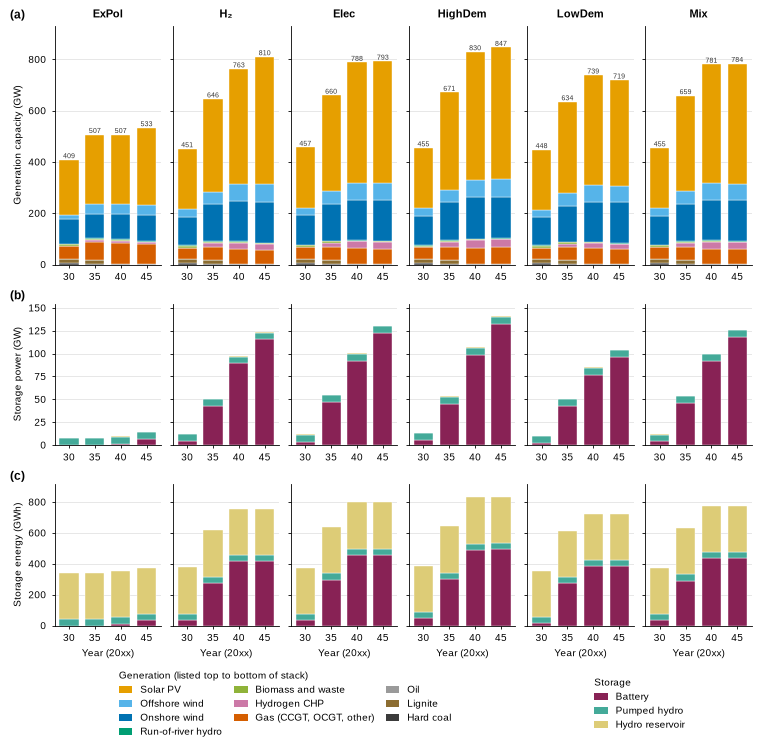

In [5]:
ROWS = [("generation_GW", GEN_ORDER, GEN_COLOR, "Generation capacity (GW)", "(a)"),
        ("storage_power_GW", STO_ORDER, STO_COLOR, "Storage power (GW)", "(b)"),
        ("storage_energy_GWh", STO_ORDER, STO_COLOR, "Storage energy (GWh)", "(c)")]
fig = plt.figure(figsize=(7.5, 7.4), constrained_layout=True)
gs = fig.add_gridspec(4, 6, height_ratios=[1.35, 0.8, 0.8, 0.42])
axes = np.empty((3, 6), dtype=object)
for r in range(3):
    for c in range(6):
        axes[r, c] = fig.add_subplot(gs[r, c], sharey=axes[r, 0] if c else None)
        if c: plt.setp(axes[r, c].get_yticklabels(), visible=False)
x = np.arange(len(YEARS))
for r, (kind, order, colors, ylabel, letter) in enumerate(ROWS):
    for c, (fam, label) in enumerate(PATHWAYS.items()):
        ax = axes[r, c]
        bottom = np.zeros(len(YEARS))
        for g in order:
            v = np.array([cap[(cap.pathway == fam) & (cap.year == y) & (cap.kind == kind) & (cap.group == g)].value.sum()
                          for y in YEARS])
            ax.bar(x, v, bottom=bottom, width=0.74, color=colors[g], edgecolor="white", linewidth=0.3)
            bottom += v
        ax.set_xticks(x); ax.set_xticklabels([f"{y % 100:02d}" for y in YEARS])
        ax.grid(axis="x", visible=False)
        if r == 0: ax.set_title(label, fontweight="bold")
        if r == 2: ax.set_xlabel("Year (20xx)")
        if c == 0:
            ax.set_ylabel(ylabel); ax.text(-0.42, 1.03, letter, transform=ax.transAxes, fontweight="bold", fontsize=8.5)
        if r == 0:   # total on top of each bar
            for xi, tot in zip(x, bottom):
                ax.text(xi, tot, f"{tot:.0f}", ha="center", va="bottom", fontsize=5.3, color="#333333")
for r, (kind, *_rest) in enumerate(ROWS):          # common y-range per row, with headroom for the totals
    ymax = cap[cap.kind == kind].groupby(["pathway", "year"]).value.sum().max()
    axes[r, 0].set_ylim(0, ymax * 1.10)
h_gen = [Patch(facecolor=GEN_COLOR[g], label=g) for g in GEN_ORDER[::-1]]
h_sto = [Patch(facecolor=STO_COLOR[g], label=g) for g in STO_ORDER]
ax_l1 = fig.add_subplot(gs[3, :4]); ax_l1.axis("off")
ax_l2 = fig.add_subplot(gs[3, 4:]); ax_l2.axis("off")
ax_l1.legend(handles=h_gen, loc="center", ncol=3, frameon=False, title="Generation (listed top to bottom of stack)",
             alignment="left", columnspacing=1.2, handlelength=1.4)
ax_l2.legend(handles=h_sto, loc="center", ncol=1, frameon=False, title="Storage", alignment="left", handlelength=1.4)
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig2_capacity.{ext}", bbox_inches="tight")
plt.show()

**Caption (suggested).** Installed capacity of German generation and storage units in the baseline of each Ariadne pathway (PyPSA-DE optimised capacities,
taken as supplied). (a) Generation capacity by technology, with the total (GW) above each bar; (b) storage discharge power; (c) storage energy capacity.
Combined-cycle, open-cycle and other gas plants are shown together; offshore wind combines AC- and DC-connected units; biomass and waste are combined.

**Notes for the methods section** (from the extraction checks, not yet verified against the PyPSA-DE network files):
* Solar, onshore and offshore wind totals equal the capacities reported in the Ariadne variables.
* In FokusH$_2$ 2045 the 38.6 GW labelled *open-cycle gas* plus the hydrogen CHP add up to the 62.6 GW of hydrogen capacity Ariadne reports; these turbines are probably hydrogen-fired but are priced at the natural gas price.
* In the Existing Policies pathway (ExPol) in 2030 about 5 GW of biogas plants appear to be labelled *gas* instead of *biomass*.
* Battery power (115.5 GW in FokusH$_2$ 2045) is about 2.4 times the stationary-battery power Ariadne reports (47.4 GW); the energy capacity (418 GWh) matches.
If these are confirmed, the grouping in this figure should be revised accordingly.